# Full-breakthrough integrator benchmark

Reads the runs written by `generate.py` and timed by `run.py` (`manifest.csv`, `results.csv`).
The RK3, CVODE SPGMR, reference, and ROS34PW2 runs are from the batch of 2026-11-03, the CVODE Dense runs from
that of 2026-10-28 (`results-2026-10-28.csv`).

Accuracy is measured by the breakthrough times $t_{50,j}$ of the adsorbing components at the outlet, against a
CVODE reference with a relative tolerance of $10^{-8}$:
$e_{50} = \max_j |t_{50,j} - t_{50,j}^{\mathrm{ref}}| / t_{50,j}^{\mathrm{ref}}$.
Runs made with the step-based input format (before 2026-10-26) label each output block with the time before the
step that produced it, so their times are shifted by that run's `TimeStep` (kept in `_legacy_simulation.json`)
before $t_{50}$ is interpolated linearly between the 2 s outputs; newer runs are labelled correctly. Every run
records the column at the same times (`WriteInterval` 2 s), so the interpolation error is common to all runs.

Cost is explained by the number of column-wide mixture-prediction calls $N_{\mathrm{mix}}$, each of which solves
the mixture equilibrium at every grid point. RK3 makes one call after each of its three stages; the CVODE
right-hand side makes two (two fixed-point passes of uptake and velocity), and RUPTURA evaluates the right-hand
side once more after every output:

- RK3: $N_{\mathrm{mix}} = 3 N_{\mathrm{steps}}$;
- CVODE: $N_{\mathrm{mix}} = 2 (N_{\mathrm{RHS}} + N_{\mathrm{RHS,lin}} + N_{\mathrm{out}})$, with the right-hand-side
  evaluations of the integrator and of the linear solver from `run.log`: the Krylov iterations with SPGMR, the
  finite-difference Jacobians with Dense.

The precision study runs CVODE with both linear solvers, SPGMR (matrix-free, no preconditioner) and Dense (the
default of `CVODELinearSolver`); every other CVODE run uses SPGMR. The paper figure shows RK3 and SPGMR; the
comparison of the two linear solvers is a separate SI figure.

The paper panels are written to `ruptura-2.0-paper/figures/benchmark/`.

In [1]:
import json
import mmap
import re
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgb

ROOT = Path.cwd().resolve()
if not (ROOT / "manifest.csv").is_file():
    raise FileNotFoundError("Run this notebook from benchmark/breakthrough after generate.py and run.py.")
REPOSITORY = ROOT.parents[2]
FIGURE_DIR = REPOSITORY / "ruptura-2.0-paper" / "figures" / "benchmark"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 13,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.width": 1.0,
    "ytick.minor.width": 1.0,
    "legend.handlelength": 1.2,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

## Data handling

In [2]:
@lru_cache(maxsize=None)
def data_column_index(path_string, heading):
    """Resolve a one-based Ruptura '# column N:' header to a NumPy index (as in marx2/create.ipynb)."""
    prefix = heading.casefold()
    with Path(path_string).open("rt", encoding="utf-8") as handle:
        for line in handle:
            if not line.startswith("#"):
                break
            if line.startswith("# column "):
                number_text, description = line[9:].split(":", 1)
                if description.strip().casefold().startswith(prefix):
                    return int(number_text) - 1
    raise ValueError(f"Column heading {heading!r} not found in {path_string}")


@lru_cache(maxsize=None)
def outlet_rows(path_string):
    """Return the last axial row (the outlet) of every output block (as in marx2/create.ipynb)."""
    rows = []
    with Path(path_string).open("rb") as handle:
        with mmap.mmap(handle.fileno(), length=0, access=mmap.ACCESS_READ) as mapped:
            block_start = 0
            while True:
                block_end = mapped.find(b"\n\n", block_start)
                if block_end < 0:
                    break
                line_start = mapped.rfind(b"\n", block_start, block_end) + 1
                line = mapped[line_start:block_end].strip()
                if line and not line.startswith(b"#"):
                    rows.append(np.array(line.split(), dtype=float))
                block_start = block_end + 2
    return np.asarray(rows)


@lru_cache(maxsize=None)
def output_time_offset(directory):
    """Time in s to add to the output labels of a run.

    The step-based binary (its run.log prints "Timestep N") labelled each output with the time before the step that
    produced it; every such run here predates the 2026-10-26 fix, so its outputs are one TimeStep late, with the
    TimeStep kept in _legacy_simulation.json. Runs of the time-based binary ("Output N") are labelled correctly.
    """
    if "Timestep " not in (directory / "run.log").read_text():
        return 0.0
    return float(json.loads((directory / "_legacy_simulation.json").read_text()).get("TimeStep", 5.0e-4))


@lru_cache(maxsize=None)
def breakthrough_times(directory):
    """t50 [s] of every adsorbing component, with the output times corrected by output_time_offset."""
    directory = ROOT / "simulations" / directory
    simulation = json.loads((directory / "simulation.json").read_text())
    total = sum(component["GasPhaseMolFraction"] for component in simulation["Components"])
    times = {}
    for index, component in enumerate(simulation["Components"]):
        if component.get("CarrierGas", False):
            continue
        path = str(directory / f"component_{index}_{component['Name']}.data")
        rows = outlet_rows(path)
        time = 60.0 * rows[:, data_column_index(path, "Time, t")] + output_time_offset(directory)
        normalized = rows[:, data_column_index(path, "Mole fraction")] / (component["GasPhaseMolFraction"] / total)
        i = int(np.argmax(normalized >= 0.5))
        times[component["Name"]] = float(np.interp(0.5, normalized[i - 1:i + 1], time[i - 1:i + 1]))
    return times


@lru_cache(maxsize=None)
def largest_outlet_ratio(directory):
    """Largest outlet mole fraction relative to the feed, over all adsorbing components and output times.

    An unstable RK3 run that does not stop with an error runs into unbounded values (BEA, monolith) or collapses to a
    zero outlet (T15) instead.
    """
    directory = ROOT / "simulations" / directory
    simulation = json.loads((directory / "simulation.json").read_text())
    total = sum(component["GasPhaseMolFraction"] for component in simulation["Components"])
    largest = 0.0
    for index, component in enumerate(simulation["Components"]):
        if component.get("CarrierGas", False):
            continue
        path = str(directory / f"component_{index}_{component['Name']}.data")
        fraction = outlet_rows(path)[:, data_column_index(path, "Mole fraction")]
        largest = max(largest, float(np.nanmax(fraction)) / (component["GasPhaseMolFraction"] / total))
    return largest


def shades(color, count, lightest, darkest):
    """`count` variants of a palette colour, from darkest (first) to lightest (last); <0 mixes in black, >0 white."""
    base = np.array(to_rgb(color))
    variants = []
    for amount in np.linspace(darkest, lightest, count):
        target = np.ones(3) if amount > 0 else np.zeros(3)
        variants.append(tuple(base + abs(amount) * (target - base)))
    return variants

In [3]:
MANIFEST = pd.read_csv(ROOT / "manifest.csv")
RESULTS = pd.read_csv(ROOT / "results.csv")
RUNS = MANIFEST.merge(RESULTS, on="directory", how="left")
# Series of the manifest that have not been run yet (the fair-CVODE series of TODO V-ITG-3) are left out.
RUNS = RUNS[RUNS["return_code"].notna()].reset_index(drop=True)
# RK3 runs above the stability limit stop with an error or run into unbounded values, and CVODE with a loose
# tolerance can stop with a convergence failure (marx-T15, SPGMR, rtol 1e-2); the references complete.
assert (RUNS.loc[RUNS["integrator"] == "reference", "return_code"] == 0).all()
# Completed RK3 runs are unstable when the outlet exceeds twice the largest roll-up of the reference of the case, or
# when no adsorbing component reaches half its feed value at the outlet.  A completed CVODE run is evaluated whatever
# its error (the monolith with Dense at rtol 1e-2 overshoots to 4.3 times the feed).
REFERENCES = RUNS[RUNS["integrator"] == "reference"].set_index("case")["directory"]
RUNS["stable"] = [run.return_code == 0
                  and (run.integrator != "rk3"
                       or 0.5 <= largest_outlet_ratio(run.directory) < 2.0 * largest_outlet_ratio(REFERENCES[run.case]))
                  for run in RUNS.itertuples()]
assert RUNS.loc[RUNS["study"] == "stability", "stable"].eq(False).all()

errors = []
calls = []
# CVODE statistics (none for RK3, or for a CVODE run that stops), for the SI comparison of the linear solvers, and the
# step statistics of ROS34PW2.
STATISTICS = {"cvode_steps": r"internal steps:\s+(\d+)", "jacobian_evaluations": r"jacobian evaluations:\s+(\d+)",
              "newton_failures": r"newton iterations:\s+\d+ \(convergence failures: (\d+)\)",
              "ros34pw2_steps": r"(?m)^  steps:\s+(\d+)", "rejected_steps": r"rejected steps:\s+(\d+)"}
statistics = {column: [] for column in STATISTICS}
for run in RUNS.itertuples():
    simulation = json.loads((ROOT / "simulations" / run.directory / "simulation.json").read_text())
    log = (ROOT / "simulations" / run.directory / "run.log").read_text()
    if run.integrator == "rk3":
        calls.append(3 * round(simulation["SimulationTime"] / simulation["TimeStep"]))
    elif run.integrator == "ros34pw2":
        # One precompute per stage after the first, and one per accepted step (ROS34PW2::printStatistics).
        match = re.search(r"mixture predictions:\s+(\d+)", log)
        calls.append(int(match.group(1)) if match else np.nan)
    else:
        outputs = round(simulation["SimulationTime"] / simulation["WriteInterval"])
        match = re.search(r"rhs evaluations:\s+(\d+) \(\+(\d+) inside the linear solver\)", log)
        # A CVODE run that stops prints no statistics.
        calls.append(2 * (int(match.group(1)) + int(match.group(2)) + outputs) if match else np.nan)
    for column, pattern in STATISTICS.items():
        found = re.search(pattern, log)
        statistics[column].append(int(found.group(1)) if found else np.nan)
    if run.study != "precision" or not run.stable:
        errors.append(np.nan)
        continue
    reference = RUNS[(RUNS["study"] == "precision") & (RUNS["case"] == run.case) & (RUNS["integrator"] == "reference")]
    reference_times = breakthrough_times(reference["directory"].iloc[0])
    times = breakthrough_times(run.directory)
    errors.append(max(abs(times[name] - reference_times[name]) / reference_times[name] for name in reference_times))
RUNS["t50_error"] = errors
RUNS["mixture_calls"] = calls
for column, values in statistics.items():
    RUNS[column] = values
RUNS["seconds_per_call"] = RUNS["elapsed_seconds"] / RUNS["mixture_calls"]
RUNS[["directory", "integrator", "time_step", "relative_tolerance", "stable", "elapsed_seconds", "t50_error", "mixture_calls"]]

,directory,integrator,time_step,relative_tolerance,stable,elapsed_seconds,t50_error,mixture_calls
0,precision/bea-alkanes-C7/rk3/dt-0.01,rk3,0.010000,NaN,True,22.063291,1.715317e-05,360000
1,precision/bea-alkanes-C7/rk3/dt-0.003125,rk3,0.003125,NaN,True,68.028266,2.047483e-07,1152000
2,precision/bea-alkanes-C7/rk3/dt-0.001,rk3,0.001000,NaN,True,198.575480,2.036199e-07,3600000
3,precision/bea-alkanes-C7/rk3/dt-0.0003125,rk3,0.000313,NaN,True,619.733500,2.034833e-07,11520000
4,precision/bea-alkanes-C7/rk3/dt-0.0001,rk3,0.000100,NaN,True,1905.749008,2.034467e-07,36000000
...,...,...,...,...,...,...,...,...
75,methods/marx-T15-langmuir/SIAST/cvode,cvode,2.000000,NaN,True,2.231225,NaN,24376
76,methods/marx-T15-langmuir/SEI/rk3,rk3,0.125000,NaN,True,4.153522,NaN,36000
77,methods/marx-T15-langmuir/SEI/cvode,cvode,2.000000,NaN,True,2.317855,NaN,28332
78,methods/marx-T15-langmuir/SPI/rk3,rk3,0.125000,NaN,True,4.460366,NaN,36000


## (a)-(c) Work-precision diagrams of the three cases, one row with a shared legend

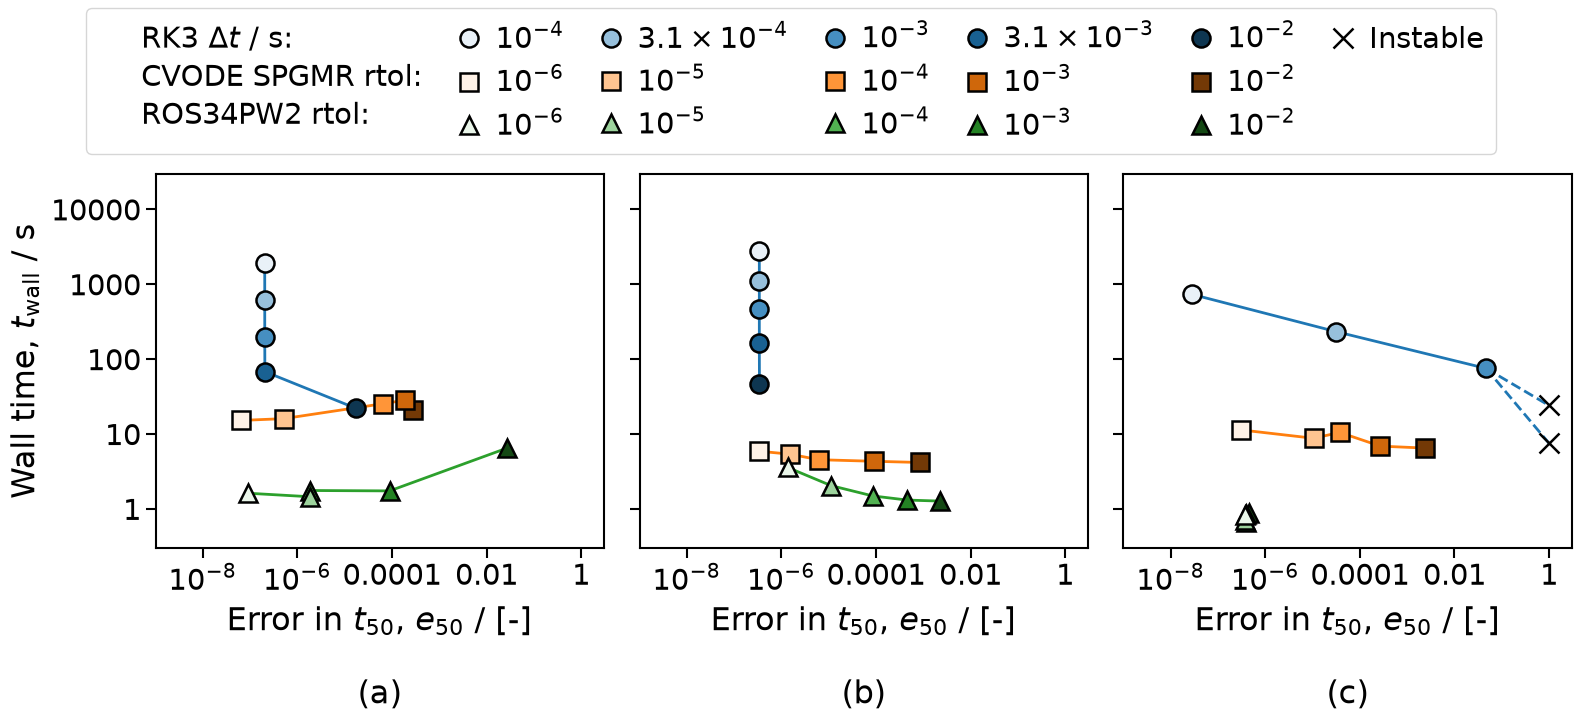

In [4]:
# One figure for the top row of the paper figure: printed at the full text width (6.27 in), so the 21-23 pt fonts
# print at about 8 pt.  The three cases share both axes and one legend.
cases = (("bea-alkanes-C7", "(a)"), ("marx-T15", "(b)"), ("monolith-400ppm-fitted-dl", "(c)"))
# One shade per setting, dark = coarse, light = fine; RK3 blue, CVODE orange, ROS34PW2 green.
RK3_TIME_STEPS = [1.0e-2, 3.125e-3, 1.0e-3, 3.125e-4, 1.0e-4]
RK3_LABELS = {1.0e-2: r"$10^{-2}$", 3.125e-3: r"$3.1\times10^{-3}$", 1.0e-3: r"$10^{-3}$",
              3.125e-4: r"$3.1\times10^{-4}$", 1.0e-4: r"$10^{-4}$"}
RK3_COLORS = dict(zip(RK3_TIME_STEPS, shades("C0", 5, 0.9, -0.55)))
CVODE_TOLERANCES = [1.0e-2, 1.0e-3, 1.0e-4, 1.0e-5, 1.0e-6]
CVODE_COLORS = dict(zip(CVODE_TOLERANCES, shades("C1", 5, 0.9, -0.55)))
ROS34PW2_COLORS = dict(zip(CVODE_TOLERANCES, shades("C2", 5, 0.9, -0.55)))

fig, axes = plt.subplots(1, 3, figsize=(16.0, 7.2), sharex=True, sharey=True)
for ax, (case, letter) in zip(axes, cases):
    precision = RUNS[(RUNS["study"] == "precision") & (RUNS["case"] == case)]
    rk3 = precision[precision["integrator"] == "rk3"].sort_values("time_step", ascending=False)
    stable = rk3[rk3["stable"]]
    unstable = rk3[~rk3["stable"]]
    cvode = precision[precision["integrator"] == "cvode"].sort_values("relative_tolerance", ascending=False)
    rosenbrock = precision[precision["integrator"] == "ros34pw2"].sort_values("relative_tolerance", ascending=False)
    ax.plot(stable["t50_error"], stable["elapsed_seconds"], color="C0", linestyle="-", linewidth=2.0, zorder=1)
    ax.plot(cvode["t50_error"], cvode["elapsed_seconds"], color="C1", linestyle="-", linewidth=2.0, zorder=1)
    ax.plot(rosenbrock["t50_error"], rosenbrock["elapsed_seconds"], color="C2", linestyle="-", linewidth=2.0, zorder=1)
    for row in stable.itertuples():
        ax.plot(row.t50_error, row.elapsed_seconds, color=RK3_COLORS[row.time_step], marker="o", markeredgecolor="black",
                linestyle="none", zorder=2)
    for row in cvode.itertuples():
        ax.plot(row.t50_error, row.elapsed_seconds, color=CVODE_COLORS[float(row.relative_tolerance)], marker="s",
                markeredgecolor="black", linestyle="none", zorder=2)
    for row in rosenbrock.itertuples():
        ax.plot(row.t50_error, row.elapsed_seconds, color=ROS34PW2_COLORS[float(row.relative_tolerance)], marker="^",
                markeredgecolor="black", linestyle="none", zorder=2)
    # Unstable runs: at e50 = 1, with the wall time extrapolated from the largest stable step (cost per step constant).
    coarsest = stable.iloc[0]
    for row in unstable.itertuples():
        wall = coarsest["elapsed_seconds"] * coarsest["time_step"] / row.time_step
        ax.plot([coarsest["t50_error"], 1.0], [coarsest["elapsed_seconds"], wall], color="C0", linestyle="--", linewidth=2.0,
                zorder=1)
        ax.plot(1.0, wall, color="black", marker="x", markersize=14, linestyle="none", zorder=3)
    # CVODE runs that stop with a convergence failure: at e50 = 1, with the wall time until the stop.
    completed = cvode[cvode["return_code"] == 0]
    for row in cvode[cvode["return_code"] != 0].itertuples():
        ax.plot([completed["t50_error"].iloc[0], 1.0], [completed["elapsed_seconds"].iloc[0], row.elapsed_seconds],
                color="C1", linestyle="--", linewidth=2.0, zorder=1)
        ax.plot(1.0, row.elapsed_seconds, color="black", marker="x", markersize=14, linestyle="none", zorder=3)
    ax.set_xlabel(r"Error in $t_{50}$, $e_{50}$ / [-]")
    ax.text(0.5, -0.35, letter, transform=ax.transAxes, ha="center", va="top")
ax = axes[0]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1.0e-9, 3.0)
ax.set_ylim(0.3, 3.0e4)
ax.set_xticks([1.0e-8, 1.0e-6, 1.0e-4, 1.0e-2, 1.0], [r"$10^{-8}$", r"$10^{-6}$", "0.0001", "0.01", "1"])
ax.set_xticks([], minor=True)
ax.set_yticks([1.0, 10.0, 100.0, 1000.0, 10000.0], ["1", "10", "100", "1000", "10000"])
ax.set_yticks([], minor=True)
ax.set_ylabel(r"Wall time, $t_{\mathrm{wall}}$ / s")

# Shared legend in three rows, RK3 time steps, CVODE tolerances, and ROS34PW2 tolerances, each from fine (left) to
# coarse (right).  The legend fills column by column, so the three rows are interleaved.
header = plt.Line2D([], [], linestyle="none")
rk3_handles = [header] + [plt.Line2D([], [], color=RK3_COLORS[value], marker="o", markeredgecolor="black",
                                     linestyle="none") for value in RK3_TIME_STEPS[::-1]]
rk3_handles += [plt.Line2D([], [], color="black", marker="x", markersize=14, linestyle="none")]
rk3_texts = [r"RK3 $\Delta t$ / s:"] + [RK3_LABELS[value] for value in RK3_TIME_STEPS[::-1]] + ["Instable"]
cvode_handles = [header] + [plt.Line2D([], [], color=CVODE_COLORS[value], marker="s", markeredgecolor="black",
                                       linestyle="none") for value in CVODE_TOLERANCES[::-1]] + [header]
cvode_texts = ["CVODE SPGMR rtol:"] + [rf"$10^{{{int(round(np.log10(value)))}}}$" for value in CVODE_TOLERANCES[::-1]] + [""]
ros34pw2_handles = [header] + [plt.Line2D([], [], color=ROS34PW2_COLORS[value], marker="^", markeredgecolor="black",
                                          linestyle="none") for value in CVODE_TOLERANCES[::-1]] + [header]
ros34pw2_texts = ["ROS34PW2 rtol:"] + [rf"$10^{{{int(round(np.log10(value)))}}}$" for value in CVODE_TOLERANCES[::-1]] + [""]
handles = [handle for row in zip(rk3_handles, cvode_handles, ros34pw2_handles) for handle in row]
texts = [text for row in zip(rk3_texts, cvode_texts, ros34pw2_texts) for text in row]
fig.legend(handles, texts, loc="upper center", ncol=len(rk3_handles), handletextpad=0.3, columnspacing=1.0,
           borderpad=0.4)
fig.subplots_adjust(left=0.105, right=0.99, bottom=0.24, top=0.76, wspace=0.08)
fig.savefig(FIGURE_DIR / "benchmark_precision.pdf", dpi=300)
plt.show()

## (e) Speed-up of CVODE and ROS34PW2 against the RK3 Courant number

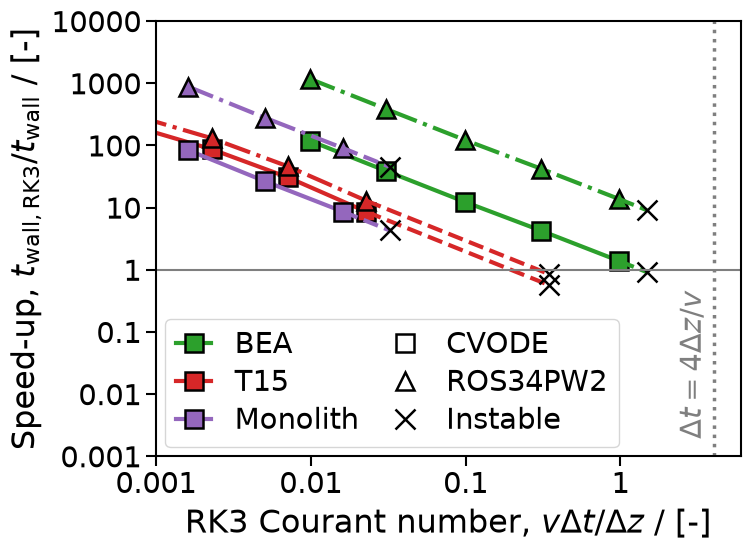

In [5]:
cases = (("bea-alkanes-C7", "BEA", "C2"), ("marx-T15", "T15", "C3"), ("monolith-400ppm-fitted-dl", "Monolith", "C4"))

fig, ax = plt.subplots()
for case, name, color in cases:
    runs = RUNS[RUNS["case"] == case]
    rk3 = runs[(runs["study"] == "precision") & (runs["integrator"] == "rk3") & runs["stable"]].sort_values("time_step")
    unstable = runs[runs["study"] == "stability"].iloc[0]
    # dz/v from the automatic CVODE step cap as RUPTURA reports it, 4 dz/v (resolveMaximumTimeStep).
    default_cvode = runs[(runs["study"] == "precision") & (runs["integrator"] == "cvode")
                         & np.isclose(runs["relative_tolerance"].astype(float), 1.0e-5)].iloc[0]
    log = (ROOT / "simulations" / default_cvode["directory"] / "run.log").read_text()
    crossing = float(re.search(r"max step ([0-9.eE+-]+) s", log).group(1)) / 4.0
    courant = rk3["time_step"] / crossing
    # CVODE (SPGMR) and ROS34PW2 at their default tolerances, rtol 1e-5 and 1e-6.
    for integrator, marker, linestyle, tolerance in (("cvode", "s", "-", 1.0e-5), ("ros34pw2", "^", "-.", 1.0e-6)):
        adaptive = runs[(runs["study"] == "precision") & (runs["integrator"] == integrator)
                        & np.isclose(runs["relative_tolerance"].astype(float), tolerance)].iloc[0]
        speedup = rk3["elapsed_seconds"] / adaptive["elapsed_seconds"]
        ax.plot(courant, speedup, color=color, linestyle=linestyle, marker=marker, markeredgecolor="black",
                label=name if integrator == "cvode" else None)
        # Smallest unstable step: speed-up extrapolated from the largest stable step (cost per step constant).
        unstable_courant = unstable["time_step"] / crossing
        unstable_speedup = speedup.iloc[-1] * courant.iloc[-1] / unstable_courant
        ax.plot([courant.iloc[-1], unstable_courant], [speedup.iloc[-1], unstable_speedup], color=color, linestyle="--")
        ax.plot(unstable_courant, unstable_speedup, color="black", marker="x", markersize=14, linestyle="none")
ax.plot([], [], color="white", marker="s", markeredgecolor="black", linestyle="-", label="CVODE")
ax.plot([], [], color="white", marker="^", markeredgecolor="black", linestyle="-.", label="ROS34PW2")
ax.plot([], [], color="black", marker="x", markersize=14, linestyle="none", label="Instable")
ax.axvline(4.0, color="C7", linestyle=":", linewidth=2.5)
ax.axhline(1.0, color="C7", linestyle="-", linewidth=1.5)
ax.text(3.7, 0.03, r"$\Delta t=4\Delta z/v$", rotation=90, ha="right", va="center", color="C7", fontsize=21)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1.0e-3, 6.0)
ax.set_ylim(1.0e-3, 1.0e4)
ax.set_xticks([1.0e-3, 1.0e-2, 1.0e-1, 1.0], ["0.001", "0.01", "0.1", "1"])
ax.set_xticks([], minor=True)
ax.set_yticks([1.0e-3, 1.0e-2, 1.0e-1, 1.0, 10.0, 100.0, 1000.0, 10000.0],
              ["0.001", "0.01", "0.1", "1", "10", "100", "1000", "10000"])
ax.set_yticks([], minor=True)
ax.set_xlabel(r"RK3 Courant number, $v\Delta t/\Delta z$ / [-]")
ax.set_ylabel(r"Speed-up, $t_{\mathrm{wall,RK3}}/t_{\mathrm{wall}}$ / [-]")
ax.legend(loc="lower left", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "benchmark_speedup.pdf", dpi=300)
plt.show()

## (d) Wall time against the number of mixture-prediction calls

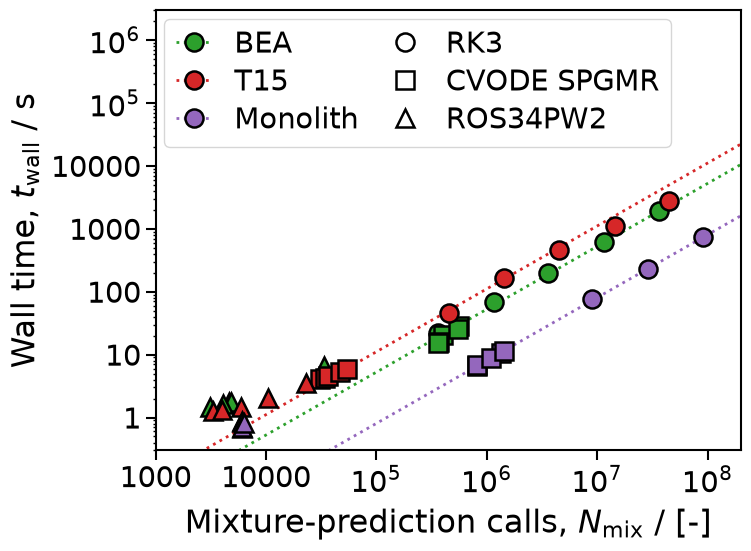

In [6]:
precision = RUNS[(RUNS["study"] == "precision") & RUNS["integrator"].isin(["rk3", "cvode"]) & RUNS["stable"]]
cases = (("bea-alkanes-C7", "BEA", "C2"), ("marx-T15", "T15", "C3"), ("monolith-400ppm-fitted-dl", "Monolith", "C4"))
calls = np.array([1.0e3, 2.0e8])

fig, ax = plt.subplots()
for case, name, color in cases:
    subset = precision[precision["case"] == case]
    # Median wall time per call: wall time proportional to the number of calls.
    ax.plot(calls, subset["seconds_per_call"].median() * calls, color=color, linestyle=":", linewidth=2.0)
    for integrator, marker in (("rk3", "o"), ("cvode", "s")):
        points = subset[subset["integrator"] == integrator]
        ax.plot(points["mixture_calls"], points["elapsed_seconds"], color=color, marker=marker, markeredgecolor="black",
                linestyle="none")
    points = RUNS[(RUNS["study"] == "precision") & (RUNS["case"] == case) & (RUNS["integrator"] == "ros34pw2")]
    ax.plot(points["mixture_calls"], points["elapsed_seconds"], color=color, marker="^", markeredgecolor="black",
            linestyle="none")
    ax.plot([], [], color=color, marker="o", markeredgecolor="black", linestyle=":", linewidth=2.0, label=name)
ax.plot([], [], color="white", marker="o", markeredgecolor="black", linestyle="none", label="RK3")
ax.plot([], [], color="white", marker="s", markeredgecolor="black", linestyle="none", label="CVODE SPGMR")
ax.plot([], [], color="white", marker="^", markeredgecolor="black", linestyle="none", label="ROS34PW2")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1.0e3, 2.0e8)
ax.set_ylim(0.3, 3.0e6)
ax.set_xticks([1.0e3, 1.0e4, 1.0e5, 1.0e6, 1.0e7, 1.0e8],
              ["1000", "10000", r"$10^{5}$", r"$10^{6}$", r"$10^{7}$", r"$10^{8}$"])
ax.set_xticks([], minor=True)
ax.set_yticks([1.0, 10.0, 100.0, 1000.0, 10000.0, 1.0e5, 1.0e6],
              ["1", "10", "100", "1000", "10000", r"$10^{5}$", r"$10^{6}$"])
ax.set_xlabel(r"Mixture-prediction calls, $N_{\mathrm{mix}}$ / [-]")
ax.set_ylabel(r"Wall time, $t_{\mathrm{wall}}$ / s")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "benchmark_evaluations.pdf", dpi=300)
plt.show()

## SI: CVODE with the SPGMR and Dense linear solvers

Work-precision of the two solvers in the three cases, and their speed-up over RK3 at the default tolerance.

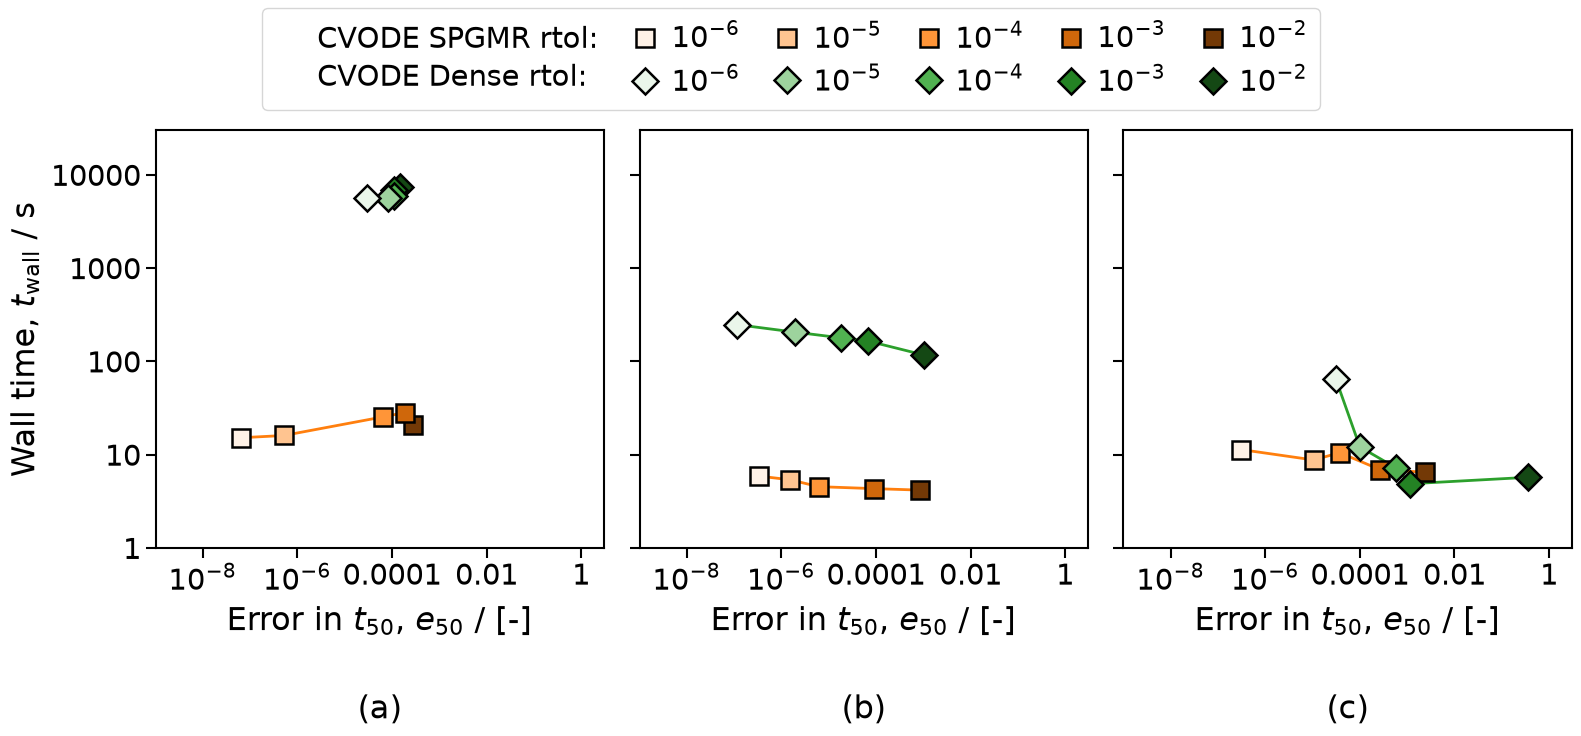

In [7]:
# SI figure: CVODE with the SPGMR and Dense linear solvers, at the full text width like panels (a)-(c).
cases = (("bea-alkanes-C7", "(a)"), ("marx-T15", "(b)"), ("monolith-400ppm-fitted-dl", "(c)"))
CVODE_TOLERANCES = [1.0e-2, 1.0e-3, 1.0e-4, 1.0e-5, 1.0e-6]
SOLVERS = {"cvode": ("SPGMR", "s", dict(zip(CVODE_TOLERANCES, shades("C1", 5, 0.9, -0.55))), "C1"),
           "cvode-dense": ("Dense", "D", dict(zip(CVODE_TOLERANCES, shades("C2", 5, 0.9, -0.55))), "C2")}

fig, axes = plt.subplots(1, 3, figsize=(16.0, 7.2), sharex=True, sharey=True)
for ax, (case, letter) in zip(axes, cases):
    precision = RUNS[(RUNS["study"] == "precision") & (RUNS["case"] == case)]
    for integrator, (name, marker, colors, line_color) in SOLVERS.items():
        series = precision[precision["integrator"] == integrator].sort_values("relative_tolerance", ascending=False)
        completed = series[series["return_code"] == 0]
        ax.plot(completed["t50_error"], completed["elapsed_seconds"], color=line_color, linestyle="-", linewidth=2.0,
                zorder=1)
        for row in completed.itertuples():
            ax.plot(row.t50_error, row.elapsed_seconds, color=colors[float(row.relative_tolerance)], marker=marker,
                    markeredgecolor="black", linestyle="none", zorder=2)
        # Runs that stop with a convergence failure: at e50 = 1, with the wall time until the stop.
        for row in series[series["return_code"] != 0].itertuples():
            ax.plot([completed["t50_error"].iloc[0], 1.0], [completed["elapsed_seconds"].iloc[0], row.elapsed_seconds],
                    color=line_color, linestyle="--", linewidth=2.0, zorder=1)
            ax.plot(1.0, row.elapsed_seconds, color="black", marker="x", markersize=14, linestyle="none", zorder=3)
    ax.set_xlabel(r"Error in $t_{50}$, $e_{50}$ / [-]")
    ax.text(0.5, -0.35, letter, transform=ax.transAxes, ha="center", va="top")
ax = axes[0]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1.0e-9, 3.0)
ax.set_ylim(1.0, 3.0e4)
ax.set_xticks([1.0e-8, 1.0e-6, 1.0e-4, 1.0e-2, 1.0], [r"$10^{-8}$", r"$10^{-6}$", "0.0001", "0.01", "1"])
ax.set_xticks([], minor=True)
ax.set_yticks([1.0, 10.0, 100.0, 1000.0, 10000.0], ["1", "10", "100", "1000", "10000"])
ax.set_yticks([], minor=True)
ax.set_ylabel(r"Wall time, $t_{\mathrm{wall}}$ / s")

# Shared legend in two rows, one per linear solver, with the tolerances from fine (left) to coarse (right).
header = plt.Line2D([], [], linestyle="none")
rows = []
for integrator, (name, marker, colors, line_color) in SOLVERS.items():
    handles = [header] + [plt.Line2D([], [], color=colors[value], marker=marker, markeredgecolor="black",
                                     linestyle="none") for value in CVODE_TOLERANCES[::-1]]
    texts = [f"CVODE {name} rtol:"] + [rf"$10^{{{int(round(np.log10(value)))}}}$" for value in CVODE_TOLERANCES[::-1]]
    rows.append((handles, texts))
handles = [handle for pair in zip(rows[0][0], rows[1][0]) for handle in pair]
texts = [text for pair in zip(rows[0][1], rows[1][1]) for text in pair]
fig.legend(handles, texts, loc="upper center", ncol=len(rows[0][0]), handletextpad=0.3, columnspacing=1.0,
           borderpad=0.4)
fig.subplots_adjust(left=0.105, right=0.99, bottom=0.24, top=0.82, wspace=0.08)
fig.savefig(FIGURE_DIR / "benchmark_dense_precision.pdf", dpi=300)
plt.show()

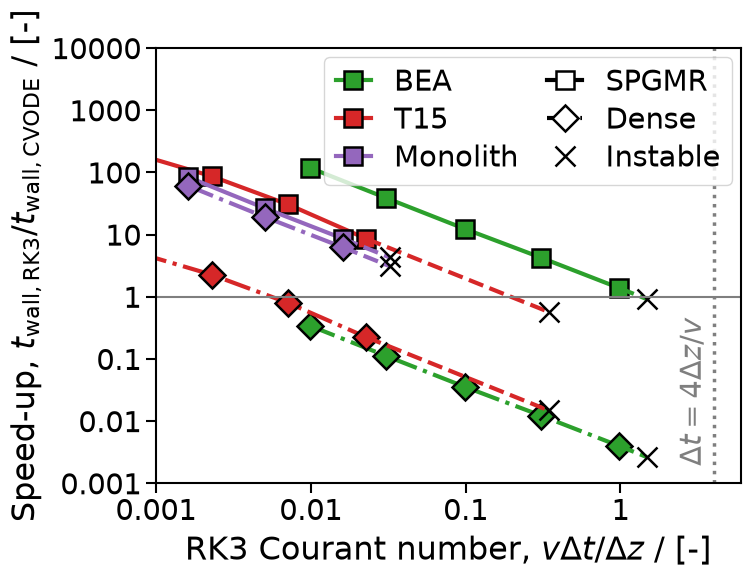

In [8]:
# SI figure: panel (e) with both linear solvers.
cases = (("bea-alkanes-C7", "BEA", "C2"), ("marx-T15", "T15", "C3"), ("monolith-400ppm-fitted-dl", "Monolith", "C4"))

fig, ax = plt.subplots()
for case, name, color in cases:
    runs = RUNS[RUNS["case"] == case]
    rk3 = runs[(runs["study"] == "precision") & (runs["integrator"] == "rk3") & runs["stable"]].sort_values("time_step")
    unstable = runs[runs["study"] == "stability"].iloc[0]
    # CVODE at the default tolerance (rtol 1e-5), SPGMR solid with squares, Dense dash-dotted with diamonds.
    for integrator, marker, linestyle in (("cvode", "s", "-"), ("cvode-dense", "D", "-.")):
        cvode = runs[(runs["study"] == "precision") & (runs["integrator"] == integrator)
                     & np.isclose(runs["relative_tolerance"].astype(float), 1.0e-5)].iloc[0]
        # dz/v from the automatic CVODE step cap as RUPTURA reports it, 4 dz/v (resolveMaximumTimeStep).
        log = (ROOT / "simulations" / cvode["directory"] / "run.log").read_text()
        crossing = float(re.search(r"max step ([0-9.eE+-]+) s", log).group(1)) / 4.0
        courant = rk3["time_step"] / crossing
        speedup = rk3["elapsed_seconds"] / cvode["elapsed_seconds"]
        ax.plot(courant, speedup, color=color, linestyle=linestyle, marker=marker, markeredgecolor="black",
                label=name if integrator == "cvode" else None)
        # Smallest unstable step: speed-up extrapolated from the largest stable step (cost per step constant).
        unstable_courant = unstable["time_step"] / crossing
        unstable_speedup = speedup.iloc[-1] * courant.iloc[-1] / unstable_courant
        ax.plot([courant.iloc[-1], unstable_courant], [speedup.iloc[-1], unstable_speedup], color=color, linestyle="--")
        ax.plot(unstable_courant, unstable_speedup, color="black", marker="x", markersize=14, linestyle="none")
ax.plot([], [], color="black", linestyle="-", marker="s", markerfacecolor="white", markeredgecolor="black",
        label="SPGMR")
ax.plot([], [], color="black", linestyle="-.", marker="D", markerfacecolor="white", markeredgecolor="black",
        label="Dense")
ax.plot([], [], color="black", marker="x", markersize=14, linestyle="none", label="Instable")
ax.axvline(4.0, color="C7", linestyle=":", linewidth=2.5)
ax.axhline(1.0, color="C7", linestyle="-", linewidth=1.5)
ax.text(3.7, 0.03, r"$\Delta t=4\Delta z/v$", rotation=90, ha="right", va="center", color="C7", fontsize=21)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1.0e-3, 6.0)
ax.set_ylim(1.0e-3, 1.0e4)
ax.set_xticks([1.0e-3, 1.0e-2, 1.0e-1, 1.0], ["0.001", "0.01", "0.1", "1"])
ax.set_xticks([], minor=True)
ax.set_yticks([1.0e-3, 1.0e-2, 1.0e-1, 1.0, 10.0, 100.0, 1000.0, 10000.0],
              ["0.001", "0.01", "0.1", "1", "10", "100", "1000", "10000"])
ax.set_yticks([], minor=True)
ax.set_xlabel(r"RK3 Courant number, $v\Delta t/\Delta z$ / [-]")
ax.set_ylabel(r"Speed-up, $t_{\mathrm{wall,RK3}}/t_{\mathrm{wall,CVODE}}$ / [-]")
ax.legend(loc="upper right", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "benchmark_dense_speedup.pdf", dpi=300)
plt.show()

## Numbers quoted in the paper

In [9]:
pd.set_option("display.width", 220)
print(RUNS[["study", "case", "integrator", "time_step", "relative_tolerance", "ncomp", "method", "elapsed_seconds",
            "t50_error", "mixture_calls", "seconds_per_call"]].to_string(index=False, float_format=lambda value: f"{value:.4g}"))

# ROS34PW2 at every tolerance of the precision study.
rosenbrock = RUNS[(RUNS["study"] == "precision") & (RUNS["integrator"] == "ros34pw2")]
print(rosenbrock.sort_values(["case", "relative_tolerance"])[
    ["case", "relative_tolerance", "return_code", "elapsed_seconds", "t50_error", "ros34pw2_steps", "rejected_steps",
     "mixture_calls"]].to_string(index=False, float_format=lambda value: f"{value:.4g}"))

# SI: the two linear solvers at every tolerance of the precision study.
solvers = RUNS[(RUNS["study"] == "precision") & RUNS["integrator"].isin(["cvode", "cvode-dense"])]
print(solvers.sort_values(["case", "relative_tolerance", "integrator"])[
    ["case", "integrator", "relative_tolerance", "return_code", "elapsed_seconds", "t50_error", "cvode_steps",
     "jacobian_evaluations", "newton_failures"]].to_string(index=False, float_format=lambda value: f"{value:.4g}"))

     study                      case  integrator  time_step  relative_tolerance  ncomp method  elapsed_seconds  t50_error  mixture_calls  seconds_per_call
 precision            bea-alkanes-C7         rk3       0.01                 NaN    NaN    NaN            22.06  1.715e-05         360000         6.129e-05
 precision            bea-alkanes-C7         rk3   0.003125                 NaN    NaN    NaN            68.03  2.047e-07        1152000         5.905e-05
 precision            bea-alkanes-C7         rk3      0.001                 NaN    NaN    NaN            198.6  2.036e-07        3600000         5.516e-05
 precision            bea-alkanes-C7         rk3  0.0003125                 NaN    NaN    NaN            619.7  2.035e-07       11520000          5.38e-05
 precision            bea-alkanes-C7         rk3     0.0001                 NaN    NaN    NaN             1906  2.034e-07       36000000         5.294e-05
 precision            bea-alkanes-C7       cvode          2           